# Day 15 | The Shape of a Cave
## Day 15 · Inside out · #30DayMapChallenge 2026

The map exposes the surveyed void of M19, cave no. 8285 on Slovenia's Migovec Plateau. A static oblique view shows the depth and shape of the passages. A true-north plan shows the same geometry from above.

Tanguy Racine, Celia Tinsley and Louise Ranken surveyed M19 on 31 July 2018. The bundled archive snapshot includes centreline shots, splays, plan walls and height annotations. The Imperial College Caving Club's [M19 Tutorial](https://imperialcaving.com/wiki/m19-tutorial) and [wall-editing guide](https://imperialcaving.com/wiki/editing-the-th2) explain how to turn these drawings into a Therion wall model. For *Inside out*, we isolate the passage volume and color it by depth below the entrance.

Therion rebuilds the wall mesh and station records. Python checks the entrance and surveyed link, clips an unsupported roof extension, assembles both views and exports the full-resolution square PNG.

## 1. Load the M19 survey inputs and build the Therion model

The centreline is in `data/M19.th`. Therion reads the two plan drawing files and the extended elevation from this same folder. The plan scraps supply passage boundaries and spot heights. Following the wall-editing guide, the maintained scraps preserve wall orientation and the drawn outlines. The configuration exports a native Loch model, DXF passage faces and SQL station and shot records.

Run this from the cave project root. Set `REBUILD_MODEL = False` to render directly from the bundled Therion outputs when the compiler is unavailable.

In [1]:
from pathlib import Path
from render_map import ROOT, MODEL, compile_model

assert Path.cwd().resolve() == ROOT
REBUILD_MODEL = True

# The input drawings remain bundled alongside the centreline so Therion
# can resolve its `input` directives without machine-specific paths.
survey_files = ("M19.th", "M19-15p.th2", "M19-234p.th2", "M19-1s.th2")
for filename in survey_files:
    assert (ROOT / "data" / filename).is_file(), filename

if REBUILD_MODEL:
    compile_model()

for filename in ("m19.lox", "m19.dxf", "m19.sql"):
    print(f"{(MODEL / filename).relative_to(ROOT)} · {(MODEL / filename).stat().st_size:,} bytes")

model\m19.lox · 134,911 bytes
model\m19.dxf · 201,535 bytes
model\m19.sql · 85,449 bytes


## 2. Establish entrance elevation and check the passage connection

Station 25 defines the local origin and 0 m depth. Survey lengths and elevations are in metres. The 2018 magnetic bearings have been corrected to true north. The first inward shot descends 4.69 m and station 25 is the highest named station. The source elevation sketches the open entrance depression above the datum. The plan-derived wall mesh extrapolates a roof there, so the display trims unsupported triangles at 0 m and leaves the cut open.

Therion's wall mesh stops short where two plan scraps meet between stations 21 and 22. The survey records a 5.02 m shot between them. The renderer draws this shot behind the wall faces so only the connection across the break remains visible as a dash.

In [2]:
import sqlite3
from contextlib import closing
import numpy as np
from render_map import clip_at_entrance, gap_shot, load_geometry

# Load only the WALLS faces, and obtain the marker from the survey
# station table so both views use the same measured location.
raw_mesh, entrance = load_geometry()
mesh = clip_at_entrance(raw_mesh)
link = gap_shot()
with closing(sqlite3.connect(":memory:")) as db:
    db.executescript((MODEL / "m19.sql").read_text(encoding="utf-8"))
    station_count, highest = db.execute(
        "SELECT COUNT(*), MAX(Z) FROM STATION WHERE NAME <> '.'"
    ).fetchone()
    (shot_length,) = db.execute(
        "SELECT s.LENGTH FROM SHOT AS s "
        "JOIN STATION AS a ON a.ID=s.FROM_ID JOIN STATION AS b ON b.ID=s.TO_ID "
        "WHERE a.NAME='21' AND b.NAME='22'"
    ).fetchone()

np.testing.assert_allclose(entrance, [0, 0, 0])
assert highest == 0 and mesh[:, :, 2].max() == 0
print(f"Entrance 25 · east, north, up: {entrance.tolist()} m")
print(f"Highest of {station_count} named stations: {highest:.2f} m")
print(f"Raw wall faces: {len(raw_mesh)} · display triangles: {len(mesh)}")
print(f"21–22 surveyed shot: {shot_length:.2f} m")

Entrance 25 · east, north, up: [0.0, 0.0, 0.0] m
Highest of 28 named stations: 0.00 m
Raw wall faces: 940 · display triangles: 954
21–22 surveyed shot: 5.02 m


## 3. Style depth and lay out both views

Face depth is the negative mean of its vertex elevations relative to station 25. The brown ramp reaches 65 m, the next 5 m increment after the deepest displayed vertex. The orthographic projection preserves relative dimensions on all three axes. The oblique mesh uses gentle directional shading to reveal the wall faces.

The north-up inset projects the same mesh vertically onto the east–north plane. An equal-aspect transform sets the scale bar, whose three ticks are 0, 5 and 10 m apart from the origin as labeled. Both views show the entrance in amber. The full legend sits beneath the plan and includes the dashed surveyed link.

The square layout places the 3D view on the left and the plan and legend on the right. The renderer checks the centered title and footer, exact Roboto faces and sizes, the footer glyphs' 5 mm bottom margin and the gap above the footer.

## 4. Export and inspect the full-resolution map

Render directly from the layout at 300 dpi on the uncropped 300 × 300 mm canvas. The preview displayed below is a thumbnail of the finished PNG, generated after export.

Roboto-Black · 30 pt
Roboto-Regular · 10 pt
Roboto-Bold · 18 pt
Footer bottom: 5.0 mm. Clear space above footer: 13.4 mm.
Clear column gap: 10.0 mm.
North arrow clears the mesh by 12.0 mm.


3543 × 3543 px at nominal 300 dpi
954 triangles. Model elevations relative to the entrance range from -61.23 to 0.00 m.
Inset 10 m bar = 23.25 mm on paper (1:430).
output\day15_inside_out_cave.png


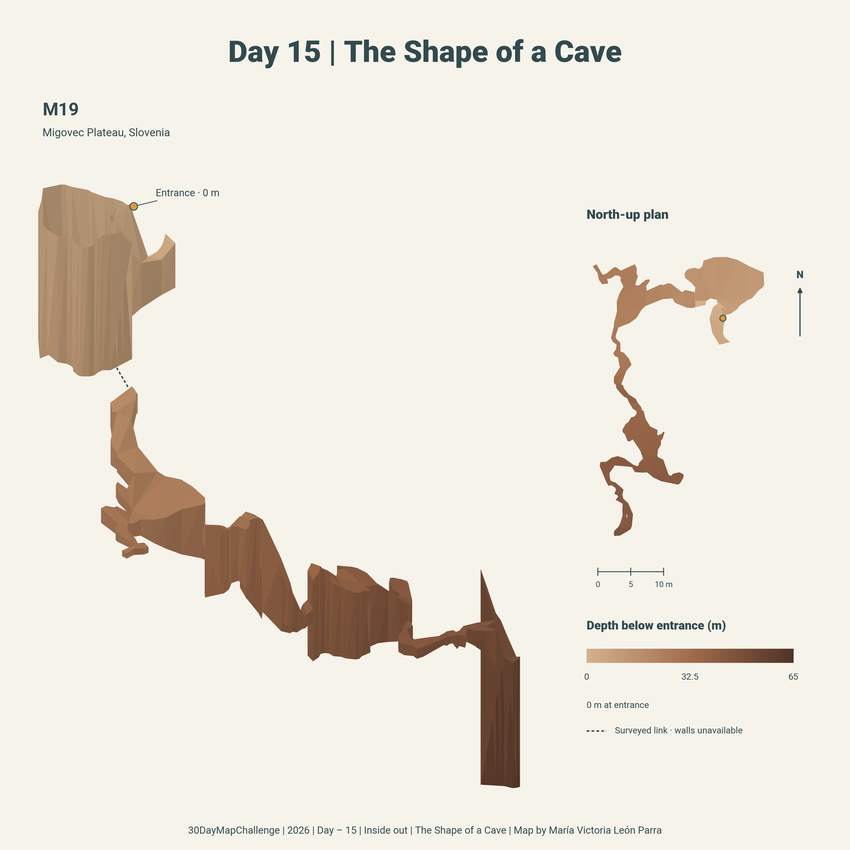

In [3]:
from io import BytesIO
from IPython.display import Image as DisplayImage, display
from PIL import Image
from render_map import main

final_png = main()
with Image.open(final_png) as png:
    assert png.size == (3543, 3543)
    assert all(abs(dpi - 300) < 0.01 for dpi in png.info["dpi"])
    print(final_png.relative_to(ROOT))
    # Resize only the notebook display copy. The file on disk is the
    # native full-resolution export from the layout.
    png.thumbnail((850, 850), Image.Resampling.LANCZOS)
    buffer = BytesIO()
    png.save(buffer, format="PNG")
display(DisplayImage(data=buffer.getvalue()))

## Sources, limitations and reproduction

The final map is [day15_inside_out_cave.png](output/day15_inside_out_cave.png), 3543 × 3543 px at nominal 300 dpi. The 10 m plan bar is 23.25 mm long at nominal print size, approximately 1:430. Print at actual size to preserve the scale.

Survey by Tanguy Racine, Celia Tinsley and Louise Ranken. Data and derivatives are CC BY-NC-SA 4.0, © ICCC / JSPDT 1974–2024. The README records the exact archive commit, the magnetic correction, the two club guides and the Roboto license. Map by María Victoria León Parra. [Data and tutorial credits](README.md#sources-and-inspiration)

The wall mesh interpolates between measured and drawn features. Sparse height control and scrap boundaries limit the accuracy of some shapes. The extended elevation and station records provide no verified above-entrance passage. The dashed 21–22 line records a surveyed connection across missing wall faces.

From the cave project root, install `requirements.txt` and Therion 6.4.1, then use **Run All**. Put Therion on PATH or set `THERION_EXE` to its executable. With `REBUILD_MODEL = False`, the bundled DXF and SQL regenerate the map without recompiling the survey. [Exact commands](README.md#local-data)